<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/2_quantum/topics_in_qm/aqm_ch03_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Topics in Quantum Mechanics* — `aqm_ch03_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# AQM Chapter 3 — Electron Dynamics in Solids: Figures
Run in Colab. Last cell auto-downloads `ch03_figures.zip`.

| Fig | Content |
|-----|--------|
| 01 | 2D Fermi surface in BZ: metal vs insulator |
| 02 | Graphene tight-binding bands (Dirac point) |
| 03 | Bloch electron: group velocity and effective mass |
| 04 | Bloch oscillations under constant E-field |
| 05 | Holes: nearly-full band and hole picture |
| 06 | Drude model: conductivity and Hall effect |
| 07 | Cyclotron orbit in k-space and real space |
| 08 | de Haas–van Alphen oscillations |
| 09 | Semi-classical EOM: E×B drift trajectory |
| 10 | Onsager quantisation: Landau level orbits |
| 11 | 3D Fermi surface topology |


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Ellipse, Circle, Polygon
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.spatial import ConvexHull
import os

plt.rcParams.update({
    'figure.facecolor': '#1e1e2e', 'axes.facecolor': '#1e1e2e',
    'text.color': '#cdd6f4', 'axes.labelcolor': '#cdd6f4',
    'xtick.color': '#cdd6f4', 'ytick.color': '#cdd6f4',
    'axes.edgecolor': '#45475a', 'grid.color': '#313244',
    'font.family': 'DejaVu Sans', 'font.size': 12,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'mathtext.fontset': 'cm',
})
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'; BG='#1e1e2e'
os.makedirs('figures/ch03', exist_ok=True)
SAVE = lambda n: plt.savefig(f'figures/ch03/{n}', dpi=150,
                              bbox_inches='tight', facecolor=BG)
print('Setup complete.')


Setup complete.


## Fig 01 — 2D Fermi Surface: Metal vs Insulator

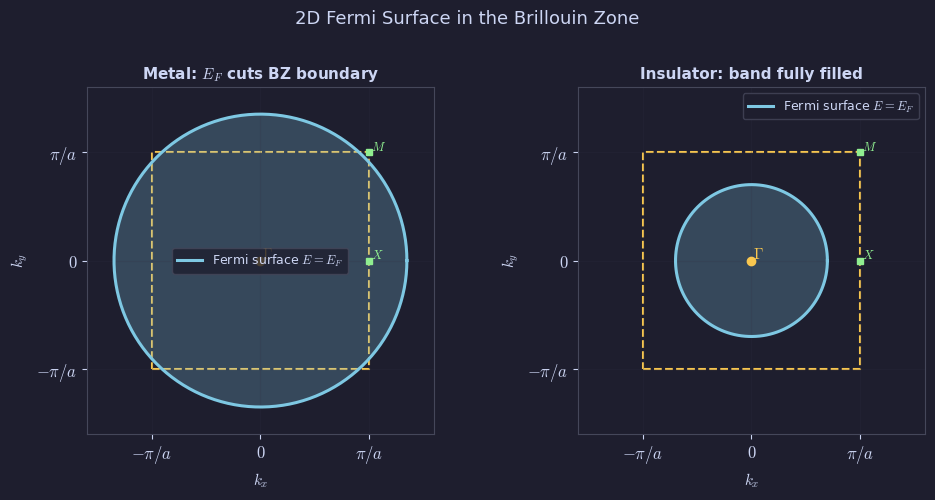

Fig 01 saved.


In [2]:

# Fig 01: 2D free electron Fermi surface + 1st Brillouin zone
# Free-electron Fermi circle for valence Z = 1 and Z = 2 in a 2D square lattice
a = 1.0

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
titles = ['$Z=1$: $k_F=\\sqrt{2\\pi}/a\\approx0.80\\,\\pi/a$ — inside the BZ (metal)',
          '$Z=2$: circle area = BZ, crosses the boundary\n(weak $V$: band overlap, metal; strong $V$: insulator)']
kF_list = [np.sqrt(2*np.pi)/a, 2*np.sqrt(np.pi)/a]   # pi kF^2 = Z/2 (2 pi/a)^2

for ax, kF, title in zip(axes, kF_list, titles):
    # BZ square boundary
    bz = plt.Polygon([[-np.pi/a,-np.pi/a],[np.pi/a,-np.pi/a],
                       [np.pi/a,np.pi/a],[-np.pi/a,np.pi/a]],
                      closed=True, fc='none', ec=YELLOW, lw=1.5, ls='--')
    ax.add_patch(bz)

    # Filled Fermi sea
    theta = np.linspace(0, 2*np.pi, 400)
    cx = kF * np.cos(theta); cy = kF * np.sin(theta)
    ax.fill(cx, cy, color=BLUE, alpha=0.25)
    ax.plot(cx, cy, color=BLUE, lw=2.2, label=r'Fermi surface $E=E_F$')

    # High-symmetry points
    ax.plot(0, 0, 'o', color=YELLOW, ms=6, zorder=5)
    ax.text(0.05, 0.05, r'$\Gamma$', color=YELLOW, fontsize=11)
    for px, py, lbl in [(np.pi/a, 0, '$X$'), (np.pi/a, np.pi/a, '$M$')]:
        ax.plot(px, py, 's', color=GREEN, ms=5, zorder=5)
        ax.text(px+0.05, py+0.05, lbl, color=GREEN, fontsize=9)

    ax.set_aspect('equal')
    ax.set_xlim(-1.6*np.pi/a, 1.6*np.pi/a)
    ax.set_ylim(-1.6*np.pi/a, 1.6*np.pi/a)
    ax.set_xlabel(r'$k_x$', fontsize=11); ax.set_ylabel(r'$k_y$', fontsize=11)
    ax.set_title(title, color='#cdd6f4', fontsize=11)
    ax.set_xticks([-np.pi/a, 0, np.pi/a])
    ax.set_xticklabels([r'$-\pi/a$', '$0$', r'$\pi/a$'])
    ax.set_yticks([-np.pi/a, 0, np.pi/a])
    ax.set_yticklabels([r'$-\pi/a$', '$0$', r'$\pi/a$'])
    ax.grid(True, alpha=0.2)
    ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')

plt.suptitle('2D Fermi Surface in the Brillouin Zone', color='#cdd6f4',
             fontsize=13, y=1.02)
plt.tight_layout()
SAVE('fig01_fermi_surface_2d.png'); plt.show(); print('Fig 01 saved.')


## Fig 02 — Graphene Band Structure

/tmp/ipykernel_45/2938588169.py:13: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  area = np.cross(a1, a2)


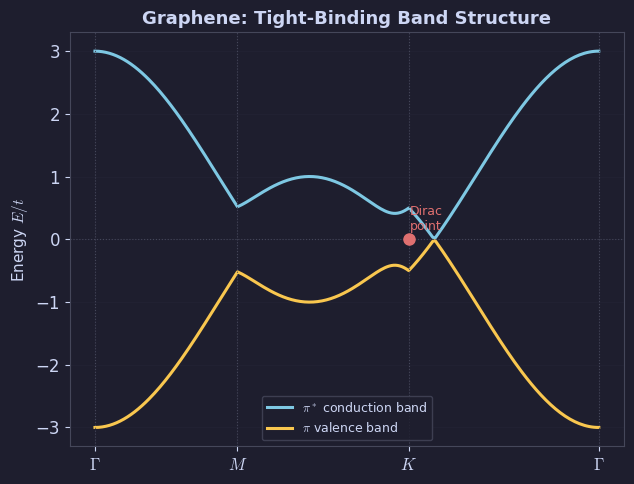

Fig 02 saved.


In [3]:

# Fig 02: Graphene tight-binding band structure along K-path
# Honeycomb lattice: 2-site unit cell, nearest-neighbour hopping t
# E±(k) = ±t * |f(k)|,  f(k) = sum_{delta} e^{ik.delta}

t = 1.0  # hopping parameter
a = 1.0  # lattice constant (C-C bond = a/sqrt(3))

# Primitive vectors of triangular Bravais lattice
a1 = a * np.array([1.0, 0.0])
a2 = a * np.array([0.5, np.sqrt(3)/2])

# Reciprocal lattice vectors
area = a1[0]*a2[1] - a1[1]*a2[0]
b1 = 2*np.pi/area * np.array([ a2[1], -a2[0]])
b2 = 2*np.pi/area * np.array([-a1[1],  a1[0]])

# Three nearest-neighbour displacement vectors (A->B)
d = a/np.sqrt(3)
deltas = d * np.array([[0,1], [np.sqrt(3)/2,-0.5], [-np.sqrt(3)/2,-0.5]])   # differences are lattice vectors

def f_graphene(kx, ky):
    return sum(np.exp(1j*(kx*dv[0]+ky*dv[1])) for dv in deltas)

# High-symmetry points
Gamma = np.array([0., 0.])
K     = (2*b1 + b2) / 3      # K point (Dirac point) = (4pi/3a, 0)
M     = b1 / 2               # M point

# k-path: Gamma -> M -> K -> Gamma
N = 80
p1 = [Gamma + s*(M-Gamma)     for s in np.linspace(0,1,N)]
p2 = [M      + s*(K-M)        for s in np.linspace(0,1,N)]
p3 = [K      + s*(Gamma-K)    for s in np.linspace(0,1,N)]
kpath = np.array(p1 + p2[1:] + p3[1:])
dist  = np.cumsum([0]+[np.linalg.norm(kpath[i+1]-kpath[i])
                       for i in range(len(kpath)-1)])

fk    = np.array([f_graphene(k[0], k[1]) for k in kpath])
E_pos = t * np.abs(fk)
E_neg = -E_pos

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(dist, E_pos, color=BLUE,   lw=2.2, label=r'$\pi^*$ conduction band')
ax.plot(dist, E_neg, color=YELLOW, lw=2.2, label=r'$\pi$ valence band')
ax.axhline(0, color='#45475a', lw=0.8, ls=':')

tick_pos  = [0, dist[N-1], dist[2*N-2], dist[-1]]
tick_labs = [r'$\Gamma$', r'$M$', r'$K$', r'$\Gamma$']
for tp in tick_pos: ax.axvline(tp, color='#45475a', lw=0.8, ls=':')
ax.set_xticks(tick_pos); ax.set_xticklabels(tick_labs, fontsize=12)

# Mark Dirac point
idx_K = 2*N-2
ax.plot(dist[idx_K], 0, 'o', color=RED, ms=8, zorder=5)
ax.text(dist[idx_K]+0.03, 0.15, 'Dirac\npoint', color=RED,
        fontsize=9, ha='left')

ax.set_ylabel(r'Energy $E/t$', fontsize=11)
ax.set_title('Graphene: Tight-Binding Band Structure', color='#cdd6f4')
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=0.2)
plt.tight_layout()
SAVE('fig02_graphene_bands.png'); plt.show(); print('Fig 02 saved.')


## Fig 03 — Group Velocity and Effective Mass

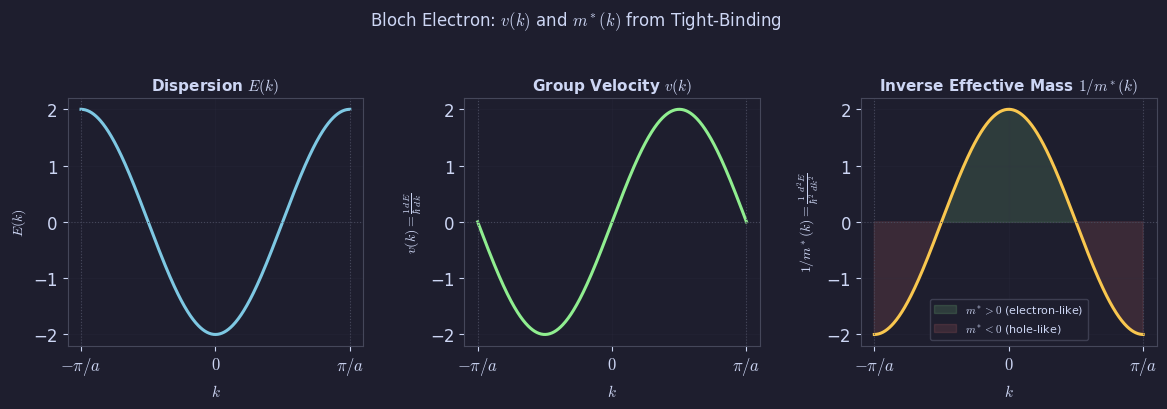

Fig 03 saved.


In [4]:

# Fig 03: Group velocity v(k) and effective mass m*(k) from TB dispersion
# E(k) = E0 - 2t cos(ka)
# v(k) = (1/hbar) dE/dk = (2ta/hbar) sin(ka)
# 1/m*(k) = (1/hbar^2) d^2E/dk^2 = (2ta^2/hbar^2) cos(ka)

a=1.; t=1.; hbar=1.; E0=0.
k = np.linspace(-np.pi/a, np.pi/a, 500)
E = E0 - 2*t*np.cos(k*a)
v = (2*t*a/hbar) * np.sin(k*a)
inv_mstar = (2*t*a**2/hbar**2) * np.cos(k*a)   # 1/m*(k)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, y, ylabel, color, title in zip(axes,
        [E, v, inv_mstar],
        [r'$E(k)$', r'$v(k) = \frac{1}{\hbar}\frac{dE}{dk}$',
         r'$1/m^*(k) = \frac{1}{\hbar^2}\frac{d^2E}{dk^2}$'],
        [BLUE, GREEN, YELLOW],
        ['Dispersion $E(k)$', 'Group Velocity $v(k)$', 'Inverse Effective Mass $1/m^*(k)$']):

    ax.plot(k, y, color=color, lw=2.2)
    ax.axhline(0, color='#45475a', lw=0.8, ls=':')
    for xb in [-np.pi/a, np.pi/a]:
        ax.axvline(xb, color='#45475a', lw=0.8, ls=':')
    ax.set_xlabel(r'$k$', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, color='#cdd6f4', fontsize=11)
    ax.set_xticks([-np.pi/a, 0, np.pi/a])
    ax.set_xticklabels([r'$-\pi/a$', '$0$', r'$\pi/a$'])
    ax.grid(True, alpha=0.2)

# Annotate effective mass sign change
axes[2].fill_between(k, inv_mstar, 0,
                     where=(inv_mstar>0), color=GREEN, alpha=0.15,
                     label=r'$m^*>0$ (electron-like)')
axes[2].fill_between(k, inv_mstar, 0,
                     where=(inv_mstar<0), color=RED, alpha=0.15,
                     label=r'$m^*<0$ (hole-like)')
axes[2].legend(fontsize=8, facecolor=BG, edgecolor='#45475a',
               labelcolor='#cdd6f4', loc='lower center')

plt.suptitle('Bloch Electron: $v(k)$ and $m^*(k)$ from Tight-Binding',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig03_group_velocity_mass.png'); plt.show(); print('Fig 03 saved.')


## Fig 04 — Bloch Oscillations

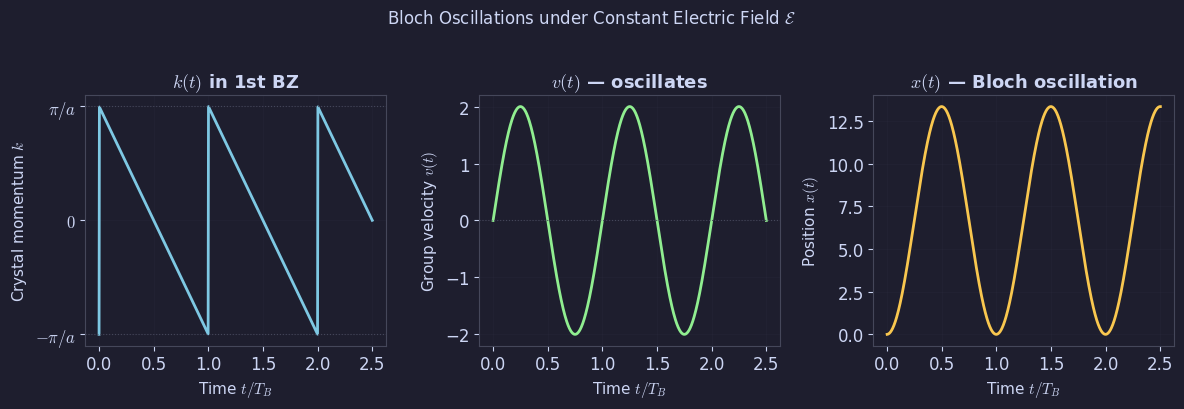

Fig 04 saved.


In [5]:

# Fig 04: Bloch oscillations — k(t) and x(t) under constant E-field
# Semi-classical: hbar dk/dt = -eE  => k(t) = k0 - eEt/hbar
# x(t) = integral v(k(t)) dt = (2ta/hbar*eE)[cos(k(t)a) - cos(k0*a)]

a=1.; t=1.; hbar=1.; e=1.; E_field=0.3; k0=-np.pi/a
T_B = 2*np.pi*hbar / (e*E_field*a)   # Bloch period
t_arr = np.linspace(0, 2.5*T_B, 800)
k_t   = (k0 - e*E_field*t_arr/hbar)

# Map k back to 1st BZ
k_bz = ((k_t + np.pi/a) % (2*np.pi/a)) - np.pi/a
v_t  = (2*t*a/hbar) * np.sin(k_bz * a)
x_t  = np.cumsum(v_t) * (t_arr[1]-t_arr[0])

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# k(t) in reduced zone (oscillates)
axes[0].plot(t_arr/T_B, k_bz, color=BLUE, lw=2.)
axes[0].axhline( np.pi/a,  color='#45475a', lw=0.8, ls=':')
axes[0].axhline(-np.pi/a,  color='#45475a', lw=0.8, ls=':')
axes[0].set_xlabel(r'Time $t/T_B$', fontsize=11)
axes[0].set_ylabel(r'Crystal momentum $k$', fontsize=11)
axes[0].set_title(r'$k(t)$ in 1st BZ', color='#cdd6f4')
axes[0].set_yticks([-np.pi/a, 0, np.pi/a])
axes[0].set_yticklabels([r'$-\pi/a$', '$0$', r'$\pi/a$'])
axes[0].grid(True, alpha=0.2)

# v(t) oscillates
axes[1].plot(t_arr/T_B, v_t, color=GREEN, lw=2.)
axes[1].axhline(0, color='#45475a', lw=0.8, ls=':')
axes[1].set_xlabel(r'Time $t/T_B$', fontsize=11)
axes[1].set_ylabel(r'Group velocity $v(t)$', fontsize=11)
axes[1].set_title(r'$v(t)$ — oscillates', color='#cdd6f4')
axes[1].grid(True, alpha=0.2)

# x(t) oscillates (Bloch oscillation)
axes[2].plot(t_arr/T_B, x_t - x_t[0], color=YELLOW, lw=2.)
axes[2].set_xlabel(r'Time $t/T_B$', fontsize=11)
axes[2].set_ylabel(r'Position $x(t)$', fontsize=11)
axes[2].set_title(r'$x(t)$ — Bloch oscillation', color='#cdd6f4')
axes[2].grid(True, alpha=0.2)

plt.suptitle(r'Bloch Oscillations under Constant Electric Field $\mathcal{E}$',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig04_bloch_oscillations.png'); plt.show(); print('Fig 04 saved.')


## Fig 05 — Holes

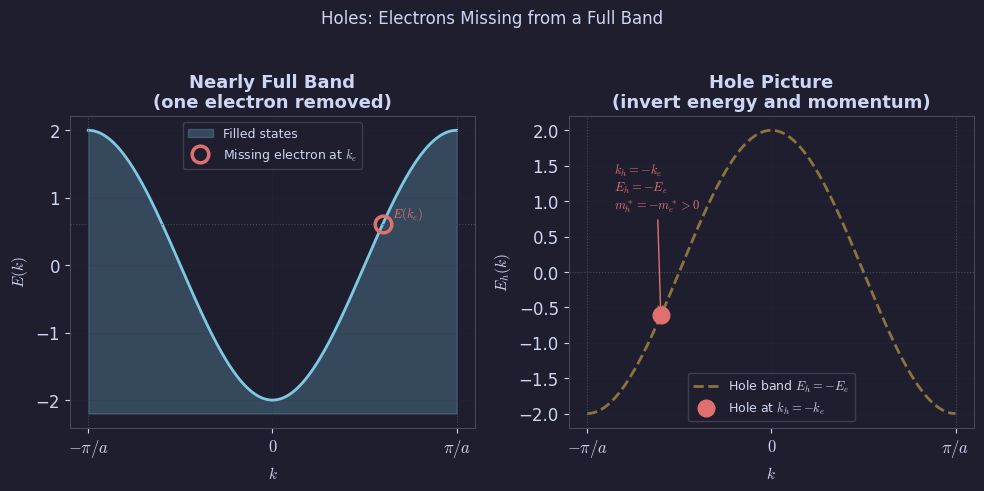

Fig 05 saved.


In [6]:

# Fig 05: Concept of holes — filled band minus one electron
# Left: nearly full band; Right: hole picture

a=1.; t=1.; E0=0.
k = np.linspace(-np.pi/a, np.pi/a, 500)
E = E0 - 2*t*np.cos(k*a)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))

# Left: nearly-full band, missing electron at k_e
k_e = 0.6*np.pi/a
idx_e = np.argmin(np.abs(k - k_e))

ax = axes[0]
ax.fill_between(k, E.min()-0.2, E, color=BLUE, alpha=0.25, label='Filled states')
ax.plot(k, E, color=BLUE, lw=2.)
# Missing state: hollow circle
ax.plot(k[idx_e], E[idx_e], 'o', mfc='none', mec=RED, mew=2.5, ms=12,
        zorder=5, label=f'Missing electron at $k_e$')
ax.axhline(E[idx_e], color='#45475a', lw=0.8, ls=':')
ax.text(k_e+0.15, E[idx_e]+0.1, r'$E(k_e)$', color=RED, fontsize=9)
for xb in [-np.pi/a, np.pi/a]: ax.axvline(xb, color='#45475a', lw=0.8, ls=':')
ax.set_xlabel(r'$k$', fontsize=11); ax.set_ylabel(r'$E(k)$', fontsize=11)
ax.set_title('Nearly Full Band\n(one electron removed)', color='#cdd6f4')
ax.set_xticks([-np.pi/a, 0, np.pi/a])
ax.set_xticklabels([r'$-\pi/a$', '$0$', r'$\pi/a$'])
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=0.2)

# Right: hole picture — inverted dispersion
E_hole = -E   # hole energy = -electron energy
k_h   = -k_e  # hole momentum = -electron momentum

ax = axes[1]
ax.plot(k, E_hole, color=YELLOW, lw=2., alpha=0.5, ls='--', label='Hole band $E_h=-E_e$')
# Hole as filled circle
ax.plot(-k_e, -E[idx_e], 'o', color=RED, ms=12, zorder=5,
        label=r'Hole at $k_h = -k_e$')
ax.axhline(0, color='#45475a', lw=0.8, ls=':')
for xb in [-np.pi/a, np.pi/a]: ax.axvline(xb, color='#45475a', lw=0.8, ls=':')

# Annotation: hole properties
ax.annotate(r'$k_h = -k_e$' '\n' r'$E_h = -E_e$' '\n' r'$m^*_h = -m^*_e > 0$',
            xy=(-k_e, -E[idx_e]), xytext=(-k_e-0.8, -E[idx_e]+1.5),
            color=RED, fontsize=9,
            arrowprops=dict(arrowstyle='->', color=RED, lw=1.))
ax.set_xlabel(r'$k$', fontsize=11); ax.set_ylabel(r'$E_h(k)$', fontsize=11)
ax.set_title('Hole Picture\n(invert energy and momentum)', color='#cdd6f4')
ax.set_xticks([-np.pi/a, 0, np.pi/a])
ax.set_xticklabels([r'$-\pi/a$', '$0$', r'$\pi/a$'])
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=0.2)

plt.suptitle('Holes: Electrons Missing from a Full Band',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig05_holes.png'); plt.show(); print('Fig 05 saved.')


## Fig 06 — Drude Model

<>:22: SyntaxWarning: invalid escape sequence '\s'
<>:22: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_45/1377836564.py:22: SyntaxWarning: invalid escape sequence '\s'
  axes[0].set_title('Drude Conductivity $\sigma(\omega)$', color='#cdd6f4')


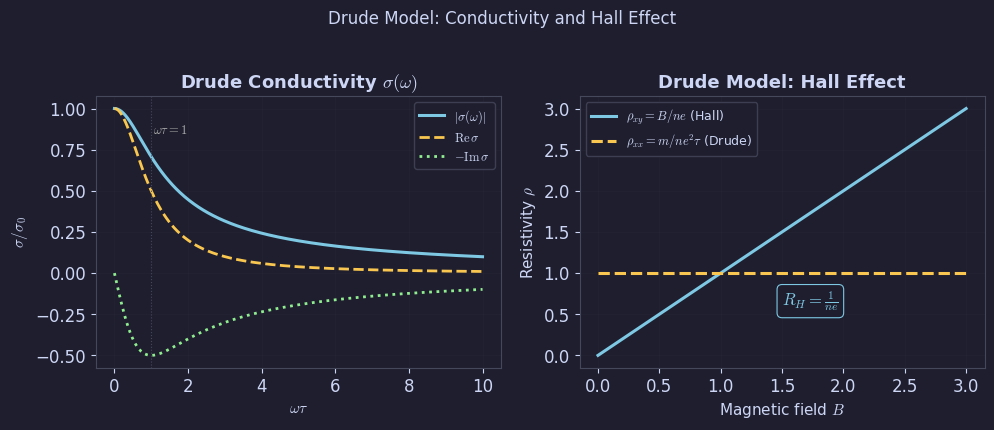

Fig 06 saved.


In [7]:

# Fig 06: Drude model — frequency-dependent conductivity
# sigma(omega) = sigma_0 / (1 - i*omega*tau)
# |sigma| and phase vs omega*tau

omega_tau = np.linspace(0, 10, 400)
sigma_0   = 1.0
sigma     = sigma_0 / (1 - 1j*omega_tau)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

# |sigma(omega)|
axes[0].plot(omega_tau, np.abs(sigma),    color=BLUE,   lw=2.2,
             label=r'$|\sigma(\omega)|$')
axes[0].plot(omega_tau, np.real(sigma),   color=YELLOW, lw=2.0, ls='--',
             label=r'$\mathrm{Re}\,\sigma$')
axes[0].plot(omega_tau, -np.imag(sigma),  color=GREEN,  lw=2.0, ls=':',
             label=r'$-\mathrm{Im}\,\sigma$')
axes[0].axvline(1, color='#45475a', lw=0.8, ls=':')
axes[0].text(1.05, 0.85, r'$\omega\tau=1$', color='#aaa', fontsize=9)
axes[0].set_xlabel(r'$\omega\tau$', fontsize=11)
axes[0].set_ylabel(r'$\sigma / \sigma_0$', fontsize=11)
axes[0].set_title('Drude Conductivity $\sigma(\omega)$', color='#cdd6f4')
axes[0].legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
axes[0].grid(True, alpha=0.2)

# Hall effect: rho_xy vs B (linear), rho_xx vs B (constant in Drude)
n_e = 1.0; e_ch = 1.0; m = 1.0; tau = 1.0
B_arr = np.linspace(0, 3, 300)
omega_c = e_ch * B_arr / m   # cyclotron frequency
# Drude with B: resistivity tensor
rho_xx  = m / (n_e * e_ch**2 * tau) * np.ones_like(B_arr)
rho_xy  = B_arr / (n_e * e_ch)   # Hall resistivity

axes[1].plot(B_arr, rho_xy, color=BLUE,   lw=2.2, label=r'$\rho_{xy} = B/ne$ (Hall)')
axes[1].plot(B_arr, rho_xx, color=YELLOW, lw=2.2, ls='--',
             label=r'$\rho_{xx} = m/ne^2\tau$ (Drude)')
axes[1].set_xlabel(r'Magnetic field $B$', fontsize=11)
axes[1].set_ylabel(r'Resistivity $\rho$', fontsize=11)
axes[1].set_title('Drude Model: Hall Effect', color='#cdd6f4')
axes[1].legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
axes[1].grid(True, alpha=0.2)
# Hall coefficient annotation
axes[1].text(1.5, 0.6, r'$R_H = \frac{1}{ne}$', color=BLUE, fontsize=12,
             bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=BLUE, lw=0.8))

plt.suptitle('Drude Model: Conductivity and Hall Effect',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig06_drude_model.png'); plt.show(); print('Fig 06 saved.')


## Fig 07 — Cyclotron Orbit

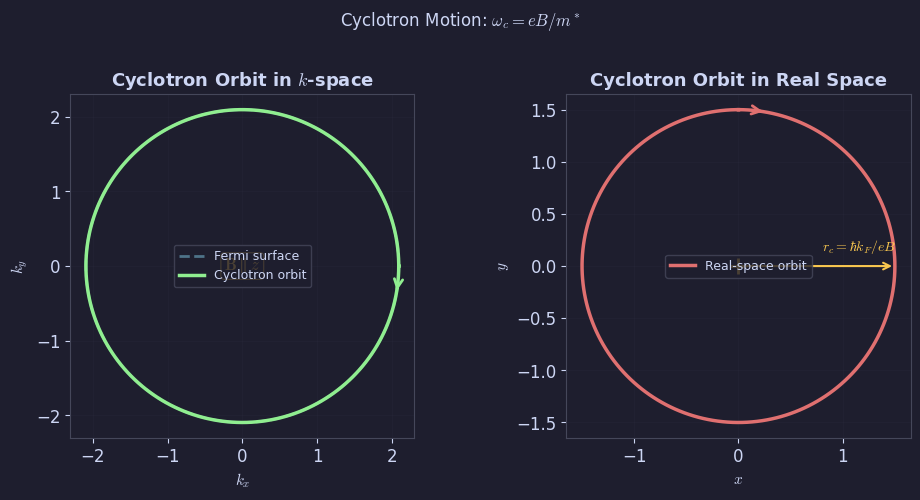

Fig 07 saved.


In [8]:

# Fig 07: Cyclotron orbit — k-space orbit on Fermi surface
# Semi-classical: hbar dk/dt = -e v x B
# For B along z: circular orbit in kx-ky plane at fixed energy

a = 1.0
t = 1.0
N_theta = 400

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))

# Left: free electron circular orbit in k-space
theta = np.linspace(0, 2*np.pi, N_theta)
kF    = np.pi / (1.5*a)   # Fermi momentum

# Cyclotron frequency: omega_c = eB/m* hbar
omega_c = 1.0
t_arr   = np.linspace(0, 2*np.pi/omega_c, N_theta)
kx_t    = kF * np.cos(-omega_c * t_arr)
ky_t    = kF * np.sin(-omega_c * t_arr)

ax = axes[0]
# Fermi circle
ax.plot(kF*np.cos(theta), kF*np.sin(theta),
        color=BLUE, lw=2., ls='--', alpha=0.5, label='Fermi surface')
# Cyclotron orbit (arrow)
ax.plot(kx_t, ky_t, color=GREEN, lw=2.5, label='Cyclotron orbit')
ax.annotate('', xy=(kx_t[10], ky_t[10]), xytext=(kx_t[9], ky_t[9]),
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2., mutation_scale=15))
# B field label
ax.text(0, 0, r'$\mathbf{B}\parallel\hat{z}$', color=YELLOW,
        ha='center', va='center', fontsize=12,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=YELLOW, lw=0.7))
ax.set_aspect('equal')
ax.set_xlabel(r'$k_x$', fontsize=11); ax.set_ylabel(r'$k_y$', fontsize=11)
ax.set_title('Cyclotron Orbit in $k$-space', color='#cdd6f4')
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=0.2)

# Right: real-space cyclotron orbit (90 degree rotated from k-space)
# x(t), y(t): circle in real space, phase-shifted by pi/2
r_c = 1.5   # cyclotron radius

ax2 = axes[1]
x_t = r_c * np.sin(omega_c * t_arr)
y_t = r_c * np.cos(omega_c * t_arr)
ax2.plot(x_t, y_t, color=RED, lw=2.5, label='Real-space orbit')
ax2.annotate('', xy=(x_t[10], y_t[10]), xytext=(x_t[9], y_t[9]),
             arrowprops=dict(arrowstyle='->', color=RED, lw=2., mutation_scale=15))
ax2.plot(0, 0, '+', color=YELLOW, ms=12, mew=2)
# Cyclotron radius annotation
ax2.annotate('', xy=(r_c, 0), xytext=(0, 0),
             arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.5))
ax2.text(r_c/2+0.05, 0.15, r'$r_c = \hbar k_F / eB$',
         color=YELLOW, fontsize=10)
ax2.set_aspect('equal')
ax2.set_xlabel(r'$x$', fontsize=11); ax2.set_ylabel(r'$y$', fontsize=11)
ax2.set_title('Cyclotron Orbit in Real Space', color='#cdd6f4')
ax2.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax2.grid(True, alpha=0.2)

plt.suptitle(r'Cyclotron Motion: $\omega_c = eB/m^*$',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig07_cyclotron_orbit.png'); plt.show(); print('Fig 07 saved.')


## Fig 08 — de Haas–van Alphen Effect

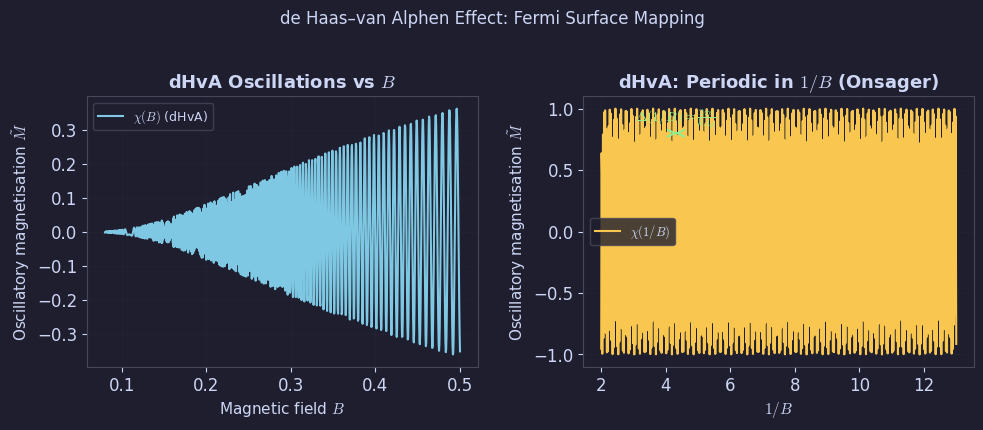

Fig 08 saved.


In [9]:

# Fig 08: de Haas-van Alphen oscillations
# Landau levels: E_n = hbar*omega_c*(n+1/2)
# Oscillations in magnetisation M vs 1/B (Onsager relation)
# dHvA period: Delta(1/B) = 2*pi*e / (hbar * A_F)
# A_F = pi*kF^2: extremal cross-sectional area of Fermi surface

hbar = 1.; e_ch = 1.; m = 1.; kF = 3.0
A_F  = np.pi * kF**2   # Fermi surface extremal area

# Susceptibility oscillations: chi ~ cos(2*pi*A_F*hbar / (e*B))
B_arr   = np.linspace(0.08, 0.5, 1000)
arg     = 2*np.pi * A_F * hbar / (e_ch * B_arr)
chi_osc = np.cos(arg)   # idealised oscillation
# Add damping (Dingle factor) and slower envelope
chi_damp = np.exp(-0.5/B_arr) * chi_osc   # Dingle damping at low B

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

# Left: oscillations vs B
axes[0].plot(B_arr, chi_damp, color=BLUE, lw=1.5, label=r'$\chi(B)$ (dHvA)')
axes[0].set_xlabel(r'Magnetic field $B$', fontsize=11)
axes[0].set_ylabel(r'Oscillatory magnetisation $\tilde{M}$', fontsize=11)
axes[0].set_title('dHvA Oscillations vs $B$', color='#cdd6f4')
axes[0].legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
axes[0].grid(True, alpha=0.2)

# Right: vs 1/B — periodic with period Delta(1/B)
invB    = np.linspace(2, 13, 1000)
arg2    = 2*np.pi * A_F * hbar / e_ch * invB
chi2    = np.cos(arg2)
period  = 2*np.pi / (A_F * hbar / e_ch)

axes[1].plot(invB, chi2, color=YELLOW, lw=1.5, label=r'$\chi(1/B)$')
# Mark one period
x0 = invB[200]
axes[1].annotate('', xy=(x0+period, 0.8), xytext=(x0, 0.8),
                 arrowprops=dict(arrowstyle='<->', color=GREEN, lw=1.5))
axes[1].text(x0+period/2, 0.9,
             r'$\Delta(1/B) = \frac{2\pi e}{\hbar A_F}$',
             color=GREEN, fontsize=10, ha='center')
axes[1].set_xlabel(r'$1/B$', fontsize=11)
axes[1].set_ylabel(r'Oscillatory magnetisation $\tilde{M}$', fontsize=11)
axes[1].set_title(r'dHvA: Periodic in $1/B$ (Onsager)', color='#cdd6f4')
axes[1].legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
axes[1].grid(True, alpha=0.2)

plt.suptitle('de Haas–van Alphen Effect: Fermi Surface Mapping',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig08_dHvA.png'); plt.show(); print('Fig 08 saved.')


## Fig 09 — Semi-classical EOM

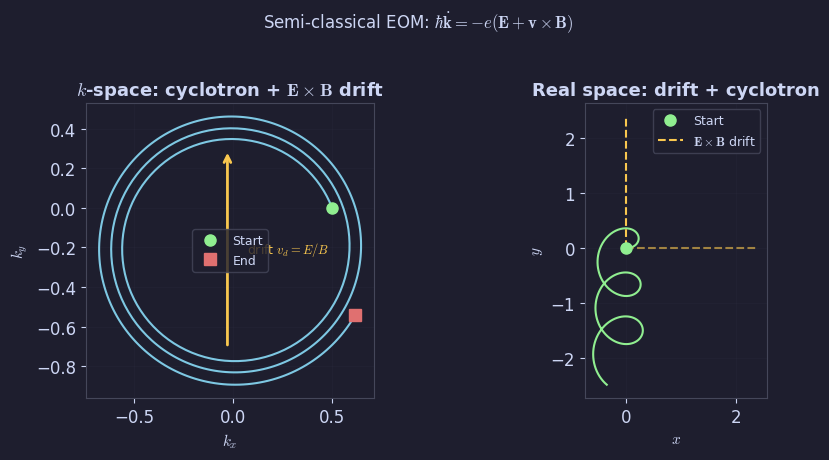

Fig 09 saved.


In [10]:

# Fig 09: Semiclassical EOM — trajectory in k-space under E and B fields
# hbar dk/dt = -e(E + v x B)
# Simulate electron trajectory in crossed E and B fields (E-cross-B drift)

hbar = 1.; e_ch = 1.; m_eff = 1.
Bz   = 1.5   # B along z
Ex   = 0.3   # E along x
omega_c = e_ch * Bz / m_eff
v_drift = Ex / Bz   # E x B drift velocity (in y direction)

dt   = 0.02
N_t  = 600
kx   = np.zeros(N_t); ky = np.zeros(N_t)
kx[0] = 0.5; ky[0] = 0.0

for i in range(N_t-1):
    vx = hbar*kx[i]/m_eff; vy = hbar*ky[i]/m_eff
    # dk/dt = -e/hbar * (E + v x B)
    dkx = (-e_ch/hbar) * (Ex + vy*Bz)
    dky = (-e_ch/hbar) * (0  - vx*Bz)
    kx[i+1] = kx[i] + dkx*dt
    ky[i+1] = ky[i] + dky*dt

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# k-space trajectory
ax = axes[0]
ax.plot(kx, ky, color=BLUE, lw=1.5)
ax.plot(kx[0], ky[0], 'o', color=GREEN, ms=8, zorder=5, label='Start')
ax.plot(kx[-1], ky[-1], 's', color=RED,   ms=8, zorder=5, label='End')
# Drift direction arrow
ax.annotate('', xy=(kx.mean(), ky.mean()+0.5),
            xytext=(kx.mean(), ky.mean()-0.5),
            arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2.))
ax.text(kx.mean()+0.1, ky.mean(), r'drift $v_d=E/B$',
        color=YELLOW, fontsize=9, va='center')
ax.set_aspect('equal')
ax.set_xlabel(r'$k_x$', fontsize=11); ax.set_ylabel(r'$k_y$', fontsize=11)
ax.set_title(r'$k$-space: cyclotron + $\mathbf{E}\times\mathbf{B}$ drift',
             color='#cdd6f4')
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=0.2)

# Real-space trajectory
t_arr = np.arange(N_t)*dt
x_r = np.cumsum(hbar*kx/m_eff)*dt
y_r = np.cumsum(hbar*ky/m_eff)*dt

ax2 = axes[1]
ax2.plot(x_r, y_r, color=GREEN, lw=1.5)
ax2.plot(x_r[0], y_r[0], 'o', color=GREEN, ms=8, zorder=5, label='Start')
# Drift line
t_long = np.linspace(0, N_t*dt, 100)
ax2.plot(Ex/Bz*t_long + x_r[0] - Ex/Bz*0,
         Ex/Bz*0*t_long + y_r[0],
         color=YELLOW, lw=1.5, ls='--', alpha=0.6)
y_drift = v_drift * t_arr
ax2.plot(x_r[0] + 0*t_arr, y_r[0] + v_drift*t_arr,
         color=YELLOW, lw=1.5, ls='--', label=r'$\mathbf{E}\times\mathbf{B}$ drift')
ax2.set_aspect('equal')
ax2.set_xlabel(r'$x$', fontsize=11); ax2.set_ylabel(r'$y$', fontsize=11)
ax2.set_title(r'Real space: drift + cyclotron', color='#cdd6f4')
ax2.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax2.grid(True, alpha=0.2)

plt.suptitle(r'Semi-classical EOM: $\hbar\dot{\mathbf{k}} = -e(\mathbf{E}+\mathbf{v}\times\mathbf{B})$',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig09_semiclassical_eom.png'); plt.show(); print('Fig 09 saved.')


## Fig 10 — Onsager Quantisation

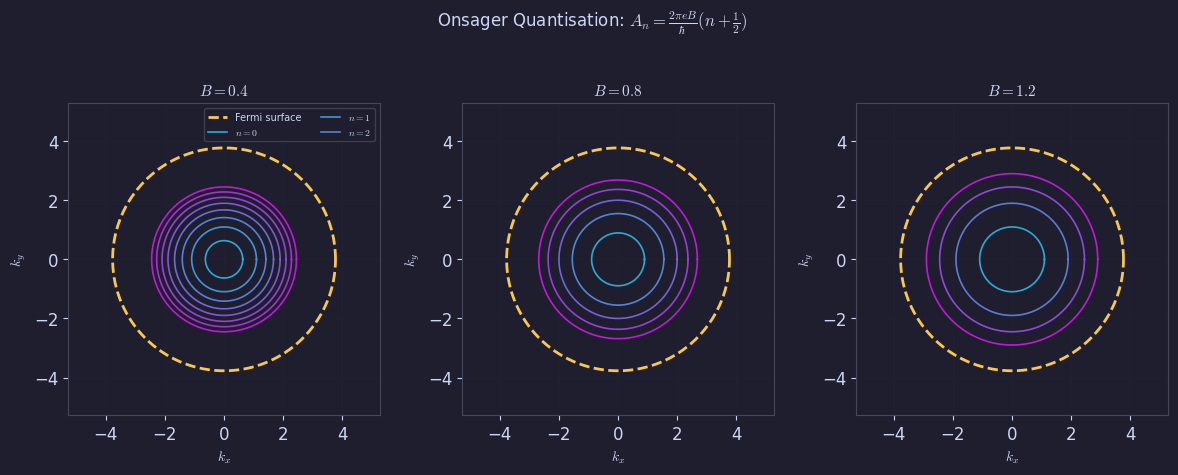

Fig 10 saved.


In [11]:

# Fig 10: Onsager quantisation
# Landau levels in k-space: closed orbits with area A_n = 2*pi*e*B/hbar*(n+1/2)
# Shows how quantised orbits nest inside the Fermi surface

a=1.; kF=1.2*np.pi/a
e_ch=1.; hbar=1.

B_vals = [0.4, 0.8, 1.2]   # different B field strengths
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))

for ax, B in zip(axes, B_vals):
    # Fermi circle
    theta = np.linspace(0, 2*np.pi, 400)
    ax.plot(kF*np.cos(theta), kF*np.sin(theta),
            color=YELLOW, lw=2., ls='--', label='Fermi surface', zorder=3)

    # Landau level orbits: A_n = 2*pi*e*B/hbar*(n+gamma), gamma=1/2
    n_max = int(kF**2 * hbar / (2*np.pi*e_ch*B)) + 2
    colors_ll = plt.cm.cool(np.linspace(0.2, 0.9, n_max+1))
    for n in range(n_max+1):
        A_n  = 2*np.pi * e_ch * B / hbar * (n + 0.5)
        r_n  = np.sqrt(A_n / np.pi)
        if r_n > 1.5*kF: break
        ax.plot(r_n*np.cos(theta), r_n*np.sin(theta),
                color=colors_ll[n % len(colors_ll)], lw=1.2, alpha=0.8,
                label=f'$n={n}$' if n < 3 else '')

    ax.set_aspect('equal')
    lim = 1.4*kF
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_xlabel(r'$k_x$', fontsize=10); ax.set_ylabel(r'$k_y$', fontsize=10)
    ax.set_title(f'$B={B}$', color='#cdd6f4', fontsize=11)
    if B == B_vals[0]:
        ax.legend(fontsize=7, facecolor=BG, edgecolor='#45475a',
                  labelcolor='#cdd6f4', loc='upper right', ncol=2)
    ax.grid(True, alpha=0.15)

plt.suptitle(r'Onsager Quantisation: $A_n = \frac{2\pi eB}{\hbar}(n+\frac{1}{2})$',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig10_onsager_quantisation.png'); plt.show(); print('Fig 10 saved.')


## Fig 11 — Fermi Surface Topology

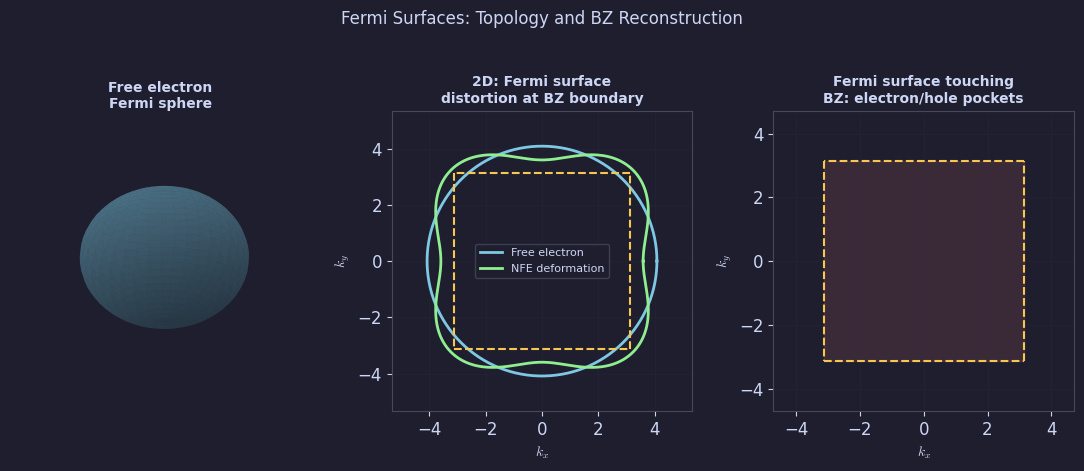

Fig 11 saved.


In [12]:

# Fig 11: 3D Fermi surfaces: free electron sphere and
# nearly-free deformation near BZ boundary (Harrison construction)
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(11, 4.5))

# Left: free electron Fermi sphere in BCC BZ
ax1 = fig.add_subplot(1,3,1, projection='3d'); ax1.set_facecolor(BG)
u = np.linspace(0, 2*np.pi, 40)
v = np.linspace(0, np.pi, 30)
kF = 1.1
xs = kF*np.outer(np.cos(u), np.sin(v))
ys = kF*np.outer(np.sin(u), np.sin(v))
zs = kF*np.outer(np.ones_like(u), np.cos(v))
ax1.plot_surface(xs, ys, zs, color=BLUE, alpha=0.35, linewidth=0, antialiased=True)
ax1.set_title('Free electron\nFermi sphere', color='#cdd6f4', fontsize=10, pad=2)
ax1.set_axis_off(); ax1.view_init(elev=20, azim=30)

# Middle: 2D cross-section showing Fermi circle + BZ distortion
ax2 = fig.add_subplot(1,3,2)
theta_fs = np.linspace(0, 2*np.pi, 500)
a = 1.

# Free electron circle
kF_2d = 1.3*np.pi/a
ax2.plot(kF_2d*np.cos(theta_fs), kF_2d*np.sin(theta_fs),
         color=BLUE, lw=2., label='Free electron')

# NFE deformation: flatten near BZ boundary
# Simple model: r(theta) = kF * (1 - delta*cos(4*theta))
delta = 0.12
r_nfe = kF_2d * (1 - delta*np.cos(4*theta_fs))
ax2.plot(r_nfe*np.cos(theta_fs), r_nfe*np.sin(theta_fs),
         color=GREEN, lw=2., label='NFE deformation')

# BZ square
bz_k = np.pi/a
for (x1,y1,x2,y2) in [(-bz_k,-bz_k,bz_k,-bz_k),(bz_k,-bz_k,bz_k,bz_k),
                        (bz_k,bz_k,-bz_k,bz_k),(-bz_k,bz_k,-bz_k,-bz_k)]:
    ax2.plot([x1,x2],[y1,y2], color=YELLOW, lw=1.5, ls='--')

ax2.set_aspect('equal')
ax2.set_xlim(-1.7*bz_k, 1.7*bz_k); ax2.set_ylim(-1.7*bz_k, 1.7*bz_k)
ax2.set_xlabel(r'$k_x$',fontsize=10); ax2.set_ylabel(r'$k_y$',fontsize=10)
ax2.set_title('2D: Fermi surface\ndistortion at BZ boundary', color='#cdd6f4', fontsize=10)
ax2.legend(fontsize=8, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax2.grid(True, alpha=0.2)

# Right: Fermi surface topology — neck formation
ax3 = fig.add_subplot(1,3,3)
ax3.set_facecolor(BG)
# Show how Fermi surface can touch BZ → splits into electron/hole pockets
theta2 = np.linspace(0, 2*np.pi, 500)
kF_large = 1.58*np.pi/a   # Fermi surface touching BZ

# Clip Fermi circle to BZ
kx_f = kF_large*np.cos(theta2)
ky_f = kF_large*np.sin(theta2)
inside = (np.abs(kx_f)<=bz_k+1e-9) & (np.abs(ky_f)<=bz_k+1e-9)

ax3.fill(kx_f*inside + bz_k*(~inside)*np.sign(kx_f),
          ky_f*inside + bz_k*(~inside)*np.sign(ky_f),
          color=RED, alpha=0.15)
for th_seg in np.split(np.where(inside)[0],
                       np.where(np.diff(np.where(inside)[0])>1)[0]+1):
    if len(th_seg)>1:
        ax3.plot(kx_f[th_seg], ky_f[th_seg], color=RED, lw=2.)
# BZ boundary
for (x1,y1,x2,y2) in [(-bz_k,-bz_k,bz_k,-bz_k),(bz_k,-bz_k,bz_k,bz_k),
                        (bz_k,bz_k,-bz_k,bz_k),(-bz_k,bz_k,-bz_k,-bz_k)]:
    ax3.plot([x1,x2],[y1,y2], color=YELLOW, lw=1.5, ls='--')
ax3.set_aspect('equal')
ax3.set_xlim(-1.5*bz_k,1.5*bz_k); ax3.set_ylim(-1.5*bz_k,1.5*bz_k)
ax3.set_xlabel(r'$k_x$',fontsize=10); ax3.set_ylabel(r'$k_y$',fontsize=10)
ax3.set_title('Fermi surface touching\nBZ: electron/hole pockets', color='#cdd6f4', fontsize=10)
ax3.grid(True, alpha=0.2)

plt.suptitle('Fermi Surfaces: Topology and BZ Reconstruction',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig11_fermi_surface_3d.png'); plt.show(); print('Fig 11 saved.')


---
## ZIP & Download

In [13]:

import shutil, os
z = shutil.make_archive('ch03_figures','zip','figures/ch03')
print(f'ZIP: {z}, {os.path.getsize(z)//1024} KB')
try:
    from google.colab import files
    files.download('ch03_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — ch03_figures.zip in working directory.')


ZIP: /home/claude/ch03_figures.zip, 1114 KB
Not in Colab — ch03_figures.zip in working directory.
